# Offensive detection: combined-data model comparison

Train on cleaned Naseza and ParsOffensive comments with one shared Neutral (0) / Offensive (1) label. Reserve a stratified test split from each source before combining the training rows. Select the model by five-fold training CV macro-F1, then report performance on each source's untouched test split separately and on the pooled test rows.

Shared texts are removed from both sources before splitting. Test results remain exploratory because both datasets were examined in earlier experiments. The selected pipeline can be saved for later use; probability calibration is not included.


## 1. Load and audit both datasets

Map Naseza Normal and ParsOffensive Neutral to class 0. Exclude unsupported or ambiguous labels, empty text, within-source duplicates and conflicting labels. Keep each source identifiable throughout the experiment.


In [1]:
from pathlib import Path
import json
import pandas as pd

RANDOM_STATE = 18
TEST_SIZE = 0.2
CV_FOLDS = 5
N_JOBS = 2
LABELS = {"Neutral": 0, "Offensive": 1}
LABEL_NAMES = {value: key for key, value in LABELS.items()}
NASEZA_LABELS = {"Normal": LABELS["Neutral"], "Offensive": LABELS["Offensive"]}

PROJECT_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents)
     if (root / "data" / "naseza.json").is_file()
     and (root / "data" / "ParsOffensive.xlsx").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Both data/naseza.json and data/ParsOffensive.xlsx are required.")

with open(PROJECT_ROOT / "data" / "naseza.json", encoding="utf-8") as file:
    naseza_rows = json.load(file)
naseza = pd.DataFrame(naseza_rows)[["text", "label"]].rename(columns={"text": "comment"})
naseza["source"] = "Naseza"
pars = pd.read_excel(
    PROJECT_ROOT / "data" / "ParsOffensive.xlsx",
    usecols=["comment", "label"],
)
pars["source"] = "ParsOffensive"
print("Source rows:", {"Naseza": len(naseza), "ParsOffensive": len(pars)})


Source rows: {'Naseza': 5731, 'ParsOffensive': 8433}


In [2]:
valid_naseza_label = naseza["label"].map(
    lambda labels: isinstance(labels, list)
    and len(labels) == 1
    and labels[0] in NASEZA_LABELS
)
print("Excluded Naseza labels:", (~valid_naseza_label).sum())
naseza = naseza.loc[valid_naseza_label].copy()
naseza["label"] = naseza["label"].map(lambda labels: NASEZA_LABELS[labels[0]])

pars["label"] = pars["label"].map(LABELS)
print("Excluded ParsOffensive labels:", pars["label"].isna().sum())
pars = pars.dropna(subset=["label"]).copy()

def audit_and_deduplicate(frame, text_column, stage):
    duplicate_mask = frame.duplicated(text_column, keep=False)
    label_counts = (
        frame[[text_column, "label"]]
        .drop_duplicates()
        [text_column].value_counts()
    )
    conflicting_texts = label_counts.index[label_counts.gt(1)]
    conflict_mask = frame[text_column].isin(conflicting_texts)
    consistent = frame.loc[~conflict_mask]
    cleaned = consistent.drop_duplicates(text_column, keep="first").copy()
    report = pd.Series({
        "input_rows": len(frame),
        "rows_in_duplicate_groups": int(duplicate_mask.sum()),
        "duplicate_text_groups": int(frame.loc[duplicate_mask, text_column].nunique()),
        "conflicting_text_groups": len(conflicting_texts),
        "conflicting_rows_removed": int(conflict_mask.sum()),
        "same_label_copies_removed": len(consistent) - len(cleaned),
        "remaining_rows": len(cleaned),
    }, name=stage)
    display(report)
    return cleaned, report




cleaned_sources = []
for source_name, frame in (("Naseza", naseza), ("ParsOffensive", pars)):
    frame = frame.loc[frame["comment"].map(lambda text: isinstance(text, str))].copy()
    frame["comment"] = frame["comment"].str.strip()
    frame = frame.loc[frame["comment"].ne("")].copy()
    frame["label"] = frame["label"].astype(int)
    frame, _ = audit_and_deduplicate(frame, "comment", source_name + "_raw")
    cleaned_sources.append(frame)

df = pd.concat(cleaned_sources, ignore_index=True)
display(pd.crosstab(df["source"], df["label"]).rename(columns=LABEL_NAMES))


Excluded Naseza labels: 14
Excluded ParsOffensive labels: 0


input_rows                   5717
rows_in_duplicate_groups       81
duplicate_text_groups          27
conflicting_text_groups         1
conflicting_rows_removed        2
same_label_copies_removed      53
remaining_rows               5662
Name: Naseza_raw, dtype: int64

input_rows                   8432
rows_in_duplicate_groups      580
duplicate_text_groups         149
conflicting_text_groups         5
conflicting_rows_removed       12
same_label_copies_removed     424
remaining_rows               7996
Name: ParsOffensive_raw, dtype: int64

label,Neutral,Offensive
source,,
Naseza,3283,2379
ParsOffensive,5096,2900


## 2. Prepare text and remove cross-source overlaps

Apply the same normalization, emoji tokens and verb handling to both sources. Keep stopwords. Remove empty and duplicate processed text within each source, then remove every text appearing in both sources before train/test splitting. This prevents the same text from appearing in one source's train and the other's test.


In [3]:
import hazm

normalizer=hazm.Normalizer()
word_tokenizer=hazm.WordTokenizer()
lemmatizer=hazm.Lemmatizer()

import string
import emoji


def remove_chars(text, chars):
    for char in chars:
        text = text.replace(char, " ")
    return text


def emoji_token(value):
    # Letters-only encoding preserves full Unicode emoji sequences through cleanup.
    encoded = [
        "".join(chr(ord("a") + int(digit, 16)) for digit in format(ord(char), "x"))
        for char in value
    ]
    return "emojitoken" + "z".join(encoded)


def preprocess(text):
    if not isinstance(text, str):
        return None
    seen_emoji = set()
    protected_tokens = set()

    def replace_emoji(value, data):
        if value in seen_emoji:
            return " "
        seen_emoji.add(value)
        token = emoji_token(value)
        protected_tokens.add(token)
        return " " + token + " "

    # Keep the first occurrence of each exact emoji sequence per comment.
    text = emoji.replace_emoji(text.lower(), replace=replace_emoji)
    text = remove_chars(text, string.punctuation + '؟،')
    text = normalizer.normalize(text).replace('آ', 'ا')
    text = remove_chars(text, '۰۱۲۳۴۵۶۷۸۹')
    tokens = [
        token if token in protected_tokens or token in lemmatizer.verbs
        else lemmatizer.lemmatize(token).split("#")[0]
        for token in word_tokenizer.tokenize(text)
    ]
    return " ".join(tokens) if tokens else None



processed_sources = []
for source_name, frame in df.groupby("source", sort=False):
    frame = frame.copy()
    frame["processed_comment"] = frame["comment"].apply(preprocess)
    print(source_name, "empty after preprocessing:", frame["processed_comment"].isna().sum())
    frame = frame.dropna(subset=["processed_comment"]).copy()
    frame, _ = audit_and_deduplicate(
        frame, "processed_comment", source_name + "_processed"
    )
    processed_sources.append(frame)

processed_by_source = {frame["source"].iloc[0]: frame for frame in processed_sources}
naseza_clean = processed_by_source["Naseza"]
pars_clean = processed_by_source["ParsOffensive"]
shared_texts = set(naseza_clean["processed_comment"]) & set(pars_clean["processed_comment"])
print("Processed texts shared by both sources:", len(shared_texts))
naseza_clean = naseza_clean.loc[
    ~naseza_clean["processed_comment"].isin(shared_texts)
].copy()
pars_clean = pars_clean.loc[
    ~pars_clean["processed_comment"].isin(shared_texts)
].copy()
df = pd.concat([naseza_clean, pars_clean], ignore_index=True)
print("Clean rows after cross-source overlap removal:", len(df))
display(pd.crosstab(df["source"], df["label"]).rename(columns=LABEL_NAMES))
display(df[["source", "comment", "processed_comment", "label"]].head())


Naseza empty after preprocessing: 0


input_rows                   5662
rows_in_duplicate_groups        8
duplicate_text_groups           4
conflicting_text_groups         0
conflicting_rows_removed        0
same_label_copies_removed       4
remaining_rows               5658
Name: Naseza_processed, dtype: int64

ParsOffensive empty after preprocessing: 0


input_rows                   7996
rows_in_duplicate_groups      133
duplicate_text_groups          47
conflicting_text_groups         3
conflicting_rows_removed       20
same_label_copies_removed      69
remaining_rows               7907
Name: ParsOffensive_processed, dtype: int64

Processed texts shared by both sources: 12
Clean rows after cross-source overlap removal: 13541


label,Neutral,Offensive
source,,
Naseza,3276,2370
ParsOffensive,5058,2837


,source,comment,processed_comment,label
0,Naseza,کف پا لیس هرچی فحش بدی شخصیتت عوض نمیشه کل گرو...,کف پا لیس هرچ فحش بدی شخصیت عوض نمیشه کل گروه ...,1
1,Naseza,کص ناموست عیرانی هزار بابا,کص ناموس عیران هزار بابا,1
2,Naseza,کص ننه بیکارت,کص ننه بیکار,1
3,Naseza,خاک بر سر تمام مملکت مردم سکوت,خاک بر سر تمام مملکت مردم سکوت,1
4,Naseza,رضا درویش رضا تخم‌گذار,رضا درویش رضا تخم‌گذار,1


## 3. Freeze a test split for each source

Reserve 20% of each source with stratification by label. Combine only their training rows. Five CV folds are stratified by source and class, so every candidate sees the same source mix. Keep both source-specific test sets untouched until evaluation.


In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold

train_parts = []
test_sets = {}
for source_name, frame in df.groupby("source", sort=False):
    if set(frame["label"]) != set(LABELS.values()):
        raise ValueError(f"Both classes are required in {source_name}.")
    train_part, test_part = train_test_split(
        frame, test_size=TEST_SIZE, random_state=RANDOM_STATE,
        stratify=frame["label"],
    )
    train_parts.append(train_part)
    test_sets[source_name] = test_part.reset_index(drop=True)
    print(source_name, "train:", len(train_part), "| reserved test:", len(test_part))

train_df = pd.concat(train_parts, ignore_index=True).sample(
    frac=1, random_state=RANDOM_STATE
).reset_index(drop=True)
X_train = train_df["processed_comment"]
y_train = train_df["label"]

all_test_texts = set().union(
    *(set(part["processed_comment"]) for part in test_sets.values())
)
assert set(X_train).isdisjoint(all_test_texts), "Text leaks into a test set."
source_label = train_df["source"] + "_" + train_df["label"].astype(str)
if source_label.value_counts().min() < CV_FOLDS:
    raise ValueError("Not enough training examples in each source/class group.")
cv = list(StratifiedKFold(
    n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE
).split(X_train, source_label))

print("Combined train rows:", len(train_df))
display(pd.crosstab(train_df["source"], train_df["label"]).rename(columns=LABEL_NAMES))
for source_name, test_part in test_sets.items():
    print(source_name, "reserved test class counts:")
    display(test_part["label"].map(LABEL_NAMES).value_counts())


Naseza train: 4516 | reserved test: 1130
ParsOffensive train: 6316 | reserved test: 1579
Combined train rows: 10832


label,Neutral,Offensive
source,,
Naseza,2620,1896
ParsOffensive,4046,2270


Naseza reserved test class counts:


label
Neutral      656
Offensive    474
Name: count, dtype: int64

ParsOffensive reserved test class counts:


label
Neutral      1012
Offensive     567
Name: count, dtype: int64

## 4. Search word and character features with five classifiers

Compare word TF-IDF and binary word counts, alone and combined with character TF-IDF (char_wb, 3 to 5-grams). Search five classifiers on the same training folds and select by macro-F1. Record Offensive recall, precision and F2, plus accuracy, to inspect the trade-offs.

Search unweighted and balanced class weights for Logistic Regression, LinearSVC, Ridge and SGD. ComplementNB has no class_weight parameter. The reserved test set is not used for selection.


In [5]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import fbeta_score, precision_score, recall_score, make_scorer
from joblib import parallel_config

pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

feature_grids = [
    {
        "vectorizer": [TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)],
        "vectorizer__min_df": [2, 5],
        "vectorizer__sublinear_tf": [False, True],
    },
    {
        "vectorizer": [FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)),
            ("char", TfidfVectorizer(
                analyzer="char_wb", ngram_range=(3, 5),
                min_df=2, sublinear_tf=True,
            )),
        ])],
        "vectorizer__word__min_df": [2, 5],
        "vectorizer__word__sublinear_tf": [False, True],
    },
    {
        "vectorizer": [CountVectorizer(ngram_range=(1, 2), max_df=0.9, binary=True)],
        "vectorizer__min_df": [1, 2],
    },
    {
        "vectorizer": [FeatureUnion([
            ("word", CountVectorizer(ngram_range=(1, 2), max_df=0.9, binary=True)),
            ("char", TfidfVectorizer(
                analyzer="char_wb", ngram_range=(3, 5),
                min_df=2, sublinear_tf=True,
            )),
        ])],
        "vectorizer__word__min_df": [1, 2],
    },
]
model_grids = [
    {
        "model": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [LinearSVC(max_iter=5000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [ComplementNB()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [RidgeClassifier()],
        "model__alpha": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [SGDClassifier(loss="log_loss", max_iter=2000, random_state=RANDOM_STATE)],
        "model__alpha": [1e-5, 1e-4, 1e-3],
        "model__class_weight": [None, "balanced"],
    },
]
param_grid = [
    {**feature_grid, **model_grid}
    for feature_grid in feature_grids
    for model_grid in model_grids
]

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={
        "offensive_f2": make_scorer(fbeta_score, beta=2, pos_label=LABELS["Offensive"], zero_division=0),
        "offensive_recall": make_scorer(recall_score, pos_label=LABELS["Offensive"], zero_division=0),
        "offensive_precision": make_scorer(precision_score, pos_label=LABELS["Offensive"], zero_division=0),
        "macro_f1": "f1_macro",
        "accuracy": "accuracy",
    },
    refit="macro_f1",
    cv=cv,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    error_score="raise",
    return_train_score=True,
    verbose=1,
)
print("Candidates:", len(list(ParameterGrid(param_grid))))
# Avoid CPU oversubscription when several fits run in parallel.
with parallel_config(backend="loky", inner_max_num_threads=1):
    grid.fit(X_train, y_train)

Candidates: 324
Fitting 5 folds for each of 324 candidates, totalling 1620 fits


## 5. Select the winner and evaluate both test sets

Rank candidates by training CV macro-F1 and refit the winner on combined train rows. Report accuracy, macro-F1 and Offensive recall for each source and for all reserved test rows pooled together. Show class reports and confusion matrices for each result.


In [6]:
cv_results = pd.DataFrame(grid.cv_results_)
def feature_name(vectorizer):
    if isinstance(vectorizer, FeatureUnion):
        word_vectorizer = dict(vectorizer.transformer_list)["word"]
        return ("binary count" if type(word_vectorizer) is CountVectorizer else "TF-IDF") + " + char_wb"
    return ("binary count" if type(vectorizer) is CountVectorizer else "TF-IDF") + " word only"


cv_results["feature_name"] = cv_results["param_vectorizer"].map(feature_name)
cv_results["model_name"] = cv_results["param_model"].map(lambda model: type(model).__name__)
cv_results = cv_results.sort_values("rank_test_macro_f1", kind="stable")
result_columns = [
    "feature_name", "model_name", "rank_test_macro_f1",
    "mean_test_offensive_f2", "std_test_offensive_f2",
    "mean_test_offensive_recall", "mean_test_offensive_precision",
    "mean_test_macro_f1", "mean_test_accuracy", "mean_train_offensive_f2",
    "mean_fit_time", "params",
]
best_per_combination = cv_results.drop_duplicates(["feature_name", "model_name"])[result_columns]
display(best_per_combination)
display(cv_results[result_columns].head(10))

best_pipeline = grid.best_estimator_
best_params = grid.best_params_
print("Selected features:", feature_name(best_pipeline.named_steps["vectorizer"]))
print("Selected model:", type(best_pipeline.named_steps["model"]).__name__)
print("Best training CV macro-F1:", grid.best_score_)
print("Best parameters:", best_params)
print("The reserved test sets remain unused for model selection.")

,feature_name,model_name,rank_test_macro_f1,mean_test_offensive_f2,std_test_offensive_f2,mean_test_offensive_recall,mean_test_offensive_precision,mean_test_macro_f1,mean_test_accuracy,mean_train_offensive_f2,mean_fit_time,params
128,TF-IDF + char_wb,LogisticRegression,1,0.798341,0.010006,0.784207,0.860457,0.858120,0.868077,0.998956,1.123714,"{'model': LogisticRegression(max_iter=2000, ra..."
141,TF-IDF + char_wb,LinearSVC,3,0.784782,0.006828,0.765003,0.875435,0.856522,0.867708,0.998620,1.083717,"{'model': LinearSVC(max_iter=5000, random_stat..."
196,TF-IDF + char_wb,SGDClassifier,10,0.802262,0.009648,0.791650,0.847824,0.855730,0.865215,0.999424,1.152940,"{'model': SGDClassifier(loss='log_loss', max_i..."
288,binary count + char_wb,LinearSVC,27,0.759165,0.012264,0.730921,0.898265,0.851009,0.864661,0.999964,1.244765,"{'model': LinearSVC(max_iter=5000, random_stat..."
280,binary count + char_wb,LogisticRegression,35,0.757403,0.009750,0.729241,0.895904,0.849508,0.863277,0.999952,1.983349,"{'model': LogisticRegression(max_iter=2000, ra..."
319,binary count + char_wb,SGDClassifier,45,0.777238,0.009037,0.759485,0.857614,0.847422,0.858938,0.985942,1.023122,"{'model': SGDClassifier(loss='log_loss', max_i..."
310,binary count + char_wb,RidgeClassifier,64,0.737525,0.011896,0.705716,0.899918,0.840954,0.856630,0.995005,1.362950,"{'model': RidgeClassifier(), 'model__alpha': 1..."
188,TF-IDF + char_wb,RidgeClassifier,65,0.760086,0.010145,0.738361,0.861720,0.840746,0.853768,0.887902,1.070649,"{'model': RidgeClassifier(), 'model__alpha': 1..."
234,binary count word only,LinearSVC,71,0.738504,0.012826,0.707879,0.893453,0.839651,0.855153,0.999952,0.396330,"{'model': LinearSVC(max_iter=5000, random_stat..."
159,TF-IDF + char_wb,ComplementNB,83,0.797311,0.013601,0.795972,0.802866,0.837450,0.846383,0.908622,0.977415,"{'model': ComplementNB(), 'model__alpha': 0.1,..."


,feature_name,model_name,rank_test_macro_f1,mean_test_offensive_f2,std_test_offensive_f2,mean_test_offensive_recall,mean_test_offensive_precision,mean_test_macro_f1,mean_test_accuracy,mean_train_offensive_f2,mean_fit_time,params
128,TF-IDF + char_wb,LogisticRegression,1,0.798341,0.010006,0.784207,0.860457,0.858120,0.868077,0.998956,1.123714,"{'model': LogisticRegression(max_iter=2000, ra..."
129,TF-IDF + char_wb,LogisticRegression,2,0.798968,0.009458,0.785167,0.859449,0.858088,0.867985,0.999004,1.084057,"{'model': LogisticRegression(max_iter=2000, ra..."
141,TF-IDF + char_wb,LinearSVC,3,0.784782,0.006828,0.765003,0.875435,0.856522,0.867708,0.998620,1.083717,"{'model': LinearSVC(max_iter=5000, random_stat..."
140,TF-IDF + char_wb,LinearSVC,4,0.784868,0.007981,0.765242,0.874764,0.856351,0.867523,0.998608,1.072293,"{'model': LinearSVC(max_iter=5000, random_stat..."
125,TF-IDF + char_wb,LogisticRegression,5,0.777288,0.013312,0.754205,0.885778,0.856139,0.868078,0.998320,1.115968,"{'model': LogisticRegression(max_iter=2000, ra..."
143,TF-IDF + char_wb,LinearSVC,6,0.783791,0.009996,0.763805,0.875499,0.856078,0.867339,0.993779,1.042009,"{'model': LinearSVC(max_iter=5000, random_stat..."
124,TF-IDF + char_wb,LogisticRegression,7,0.776429,0.013333,0.753005,0.886850,0.856050,0.868078,0.998236,1.045169,"{'model': LogisticRegression(max_iter=2000, ra..."
144,TF-IDF + char_wb,LinearSVC,8,0.797616,0.008327,0.784447,0.855099,0.856029,0.865954,0.999172,1.102018,"{'model': LinearSVC(max_iter=5000, random_stat..."
145,TF-IDF + char_wb,LinearSVC,9,0.797579,0.008452,0.784446,0.854894,0.855939,0.865862,0.999148,1.077086,"{'model': LinearSVC(max_iter=5000, random_stat..."
196,TF-IDF + char_wb,SGDClassifier,10,0.802262,0.009648,0.791650,0.847824,0.855730,0.865215,0.999424,1.152940,"{'model': SGDClassifier(loss='log_loss', max_i..."


Selected features: TF-IDF + char_wb
Selected model: LogisticRegression
Best training CV macro-F1: 0.858119716267544
Best parameters: {'model': LogisticRegression(max_iter=2000, random_state=18), 'model__C': 10.0, 'model__class_weight': 'balanced', 'vectorizer': FeatureUnion(transformer_list=[('word',
                                TfidfVectorizer(max_df=0.9,
                                                ngram_range=(1, 2))),
                               ('char',
                                TfidfVectorizer(analyzer='char_wb', min_df=2,
                                                ngram_range=(3, 5),
                                                sublinear_tf=True))]), 'vectorizer__word__min_df': 2, 'vectorizer__word__sublinear_tf': False}
The reserved test sets remain unused for model selection.


Naseza classification report:
              precision    recall  f1-score   support

     Neutral      0.862     0.945     0.902       656
   Offensive      0.912     0.791     0.847       474

    accuracy                          0.881      1130
   macro avg      0.887     0.868     0.875      1130
weighted avg      0.883     0.881     0.879      1130



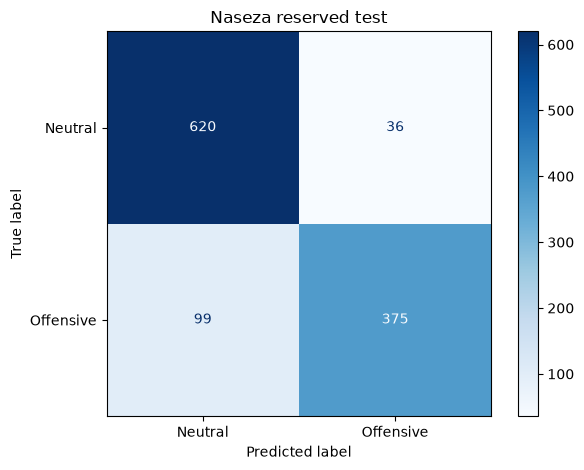

ParsOffensive classification report:
              precision    recall  f1-score   support

     Neutral      0.891     0.902     0.896      1012
   Offensive      0.821     0.802     0.812       567

    accuracy                          0.866      1579
   macro avg      0.856     0.852     0.854      1579
weighted avg      0.866     0.866     0.866      1579



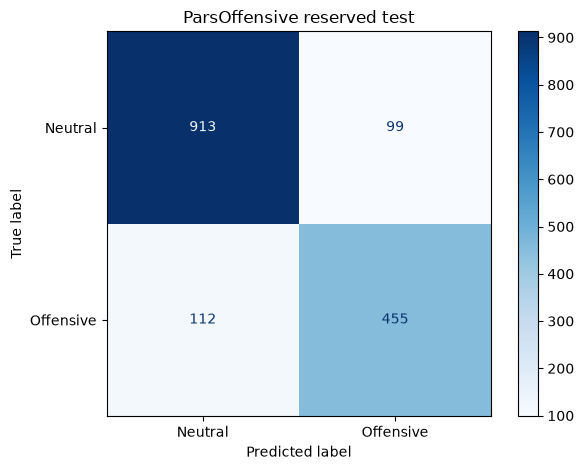

Overall classification report:
              precision    recall  f1-score   support

     Neutral      0.879     0.919     0.899      1668
   Offensive      0.860     0.797     0.828      1041

    accuracy                          0.872      2709
   macro avg      0.870     0.858     0.863      2709
weighted avg      0.872     0.872     0.871      2709



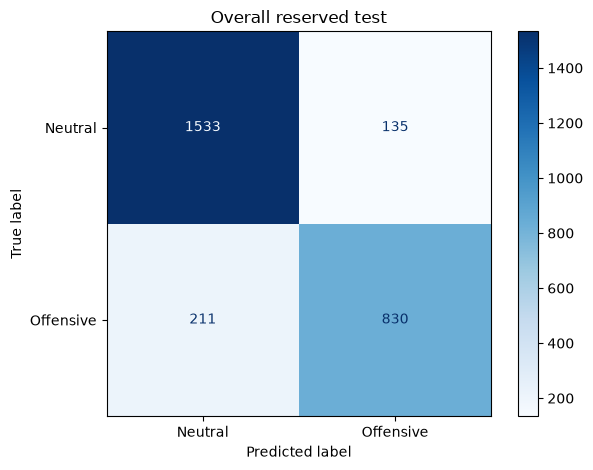

,source,rows,accuracy,macro_f1,offensive_recall
0,Naseza,1130,0.880531,0.874638,0.791139
1,ParsOffensive,1579,0.866371,0.854096,0.802469
2,Overall,2709,0.872278,0.863055,0.797310


In [9]:
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    f1_score, recall_score,
)
import matplotlib.pyplot as plt

class_ids = list(LABEL_NAMES)
class_names = [LABEL_NAMES[class_id] for class_id in class_ids]
test_scores = []
all_actual = []
all_predicted = []

def evaluate_test(name, actual, predicted):
    test_scores.append({
        "source": name,
        "rows": len(actual),
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(actual, predicted, average="macro"),
        "offensive_recall": recall_score(
            actual, predicted, pos_label=LABELS["Offensive"]
        ),
    })
    print(name, "classification report:")
    print(classification_report(
        actual, predicted, labels=class_ids,
        target_names=class_names, digits=3, zero_division=0,
    ))
    ConfusionMatrixDisplay.from_predictions(
        actual, predicted, labels=class_ids,
        display_labels=class_names, cmap="Blues", values_format="d",
    )
    plt.title(name + " reserved test")
    plt.tight_layout()
    plt.show()

for source_name, test_part in test_sets.items():
    actual = test_part["label"].reset_index(drop=True)
    predicted = pd.Series(best_pipeline.predict(test_part["processed_comment"]))
    all_actual.append(actual)
    all_predicted.append(predicted)
    evaluate_test(source_name, actual, predicted)

evaluate_test(
    "Overall",
    pd.concat(all_actual, ignore_index=True),
    pd.concat(all_predicted, ignore_index=True),
)
display(pd.DataFrame(test_scores))


## 6. Save the selected model

Save the fitted vectorizer and classifier together. This pipeline expects text processed by the same `preprocess` function above.


In [10]:
import joblib

model_path = PROJECT_ROOT / "web/services/models/offensive_detection_pipeline.joblib"
joblib.dump(best_pipeline, model_path)
print(f"Saved model to {model_path}")


Saved model to f:\Roham\projects\Web\Django\vazheh-kav\web\services\models\offensive_detection_pipeline.joblib
